### this script select publications that involve both high-income and low-income countries

In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from random import sample
from matplotlib.lines import Line2D
import matplotlib.colors as colors
import matplotlib.patches as mpatches

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_meta.csv'

In [3]:
author_df=pd.read_pickle(author_path)

In [4]:
ingroup_df=pd.read_csv(ingroup_path)
ingroupdict = dict(zip(ingroup_df['Code'],ingroup_df['ingroup_08-20']))

In [6]:
author_df['ingroup']=author_df['Code'].map(ingroupdict)

In [17]:
high_df=author_df[author_df.ingroup=='H'][['id']].drop_duplicates() #select papers with high income authors
low_df=author_df[author_df.ingroup=='L'][['id']].drop_duplicates() #select papers with low income authors
merge_df=high_df.merge(low_df,on='id',how='inner')
hl_df=merge_df.merge(author_df,on='id',how='inner') #authors of the high-low publications

### the authorship distribution of high-low pairs

In [21]:
def norm(df):
    df = df.groupby(['year','ingroup']).size(
    ).reset_index(name='count'
                 ).pivot(index='year',columns='ingroup',values='count')
    df=df.div(df.sum(axis=1), axis=0).reset_index()
    df = df.melt(id_vars='year', var_name='ingroup', value_name='count')
    return df

In [22]:
first_df=hl_df[hl_df.role=='F']
first_df=norm(first_df)

In [23]:
last_df=hl_df[hl_df.role=='L']
last_df=norm(last_df)

In [24]:
middle_df=hl_df[hl_df.role=='M']
middle_df=norm(middle_df)

In [25]:
def plot(df, ax):
    color={'H':'#E01A27','UM':'#F88A4D','LM':'#5DC97C','L':'#23A5D9'}
    sns.lineplot(x='year',y='count',hue='ingroup',data=df,ax=ax,legend=False,
                palette=color,hue_order=['H','UM','LM','L'])
    return ax

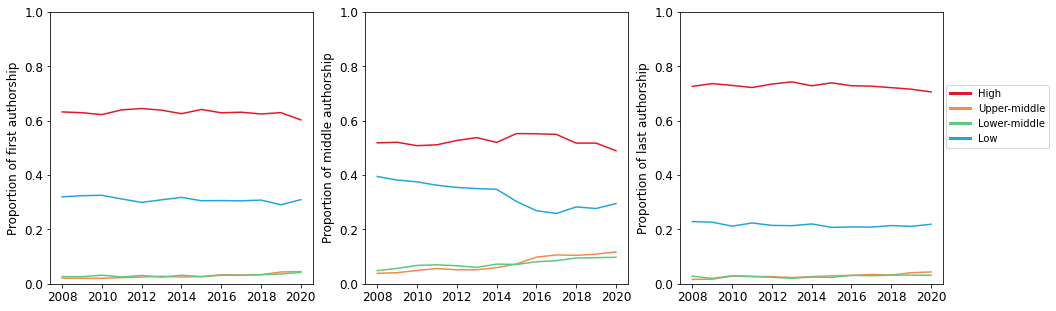

In [27]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
ax[0]=plot(first_df,ax[0])
ax[0].set_ylim(0,1)
ax[0].set_xlabel("")
ax[0].tick_params(axis='both', which='major', labelsize=12)
ax[0].set_ylabel("Proportion of first authorship",fontsize=12)

ax[1]=plot(middle_df,ax[1])
ax[1].set_ylim(0,1)
ax[1].set_xlabel("")
ax[1].tick_params(axis='both', which='major', labelsize=12)
ax[1].set_ylabel("Proportion of middle authorship",fontsize=12)

ax[2]=plot(last_df,ax[2])
ax[2].set_ylim(0,1)
ax[2].set_xlabel("")
ax[2].tick_params(axis='both', which='major', labelsize=12)
ax[2].set_ylabel("Proportion of last authorship",fontsize=12)

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['High', 'Upper-middle', 'Lower-middle','Low']
plt.legend(lines, labels,loc=(1.01,0.5))

In [32]:
shuffle_path='../../data/dropbox/LaborDivision/Data/deriveddata/authorship_shuffle/authorship_shuffle.pkl'
shuffle_df=pd.read_pickle(shuffle_path)

In [37]:
shuffle_df=shuffle_df[shuffle_df['id'].isin(hl_df['id'].values)]

In [43]:
raw_role=hl_df.groupby(['year','Code','role']).size().reset_index(name='raw')

In [60]:
sfl_role=shuffle_df.groupby(['year','cntry','role']).size().reset_index(name='shuffle')
sfl_role=sfl_role.rename(columns={'cntry':'Code'})
sfl_role['shuffle']=sfl_role['shuffle']/20

In [61]:
merge_role=raw_role.merge(sfl_role,on=['year','Code','role'])
merge_role['ratio']=merge_role['raw']/merge_role['shuffle']
merge_role['ingroup']=merge_role['Code'].map(ingroupdict)

In [62]:
merge_role.head()

,year,Code,role,raw,shuffle,ratio,ingroup
0,2008,AFG,F,1,5.75,0.173913,L
1,2008,AFG,L,5,6.05,0.826446,L
2,2008,AFG,M,30,24.20,1.239669,L
3,2008,AGO,M,1,0.70,1.428571,LM
4,2008,ALB,M,2,1.75,1.142857,UM


In [58]:
def plot_line(data,authorship,ax,title):
    df=data[data.role==authorship]
    sns.lineplot(x='year',y='ratio',hue='ingroup',data=df,ax=ax,legend=False,
             hue_order=['H','UM','LM','L'],
             palette={'H':'#E01A27','UM':'#F88A4D','LM':'#5DC97C','L':'#23A5D9'})
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title,fontsize=12)
    return ax

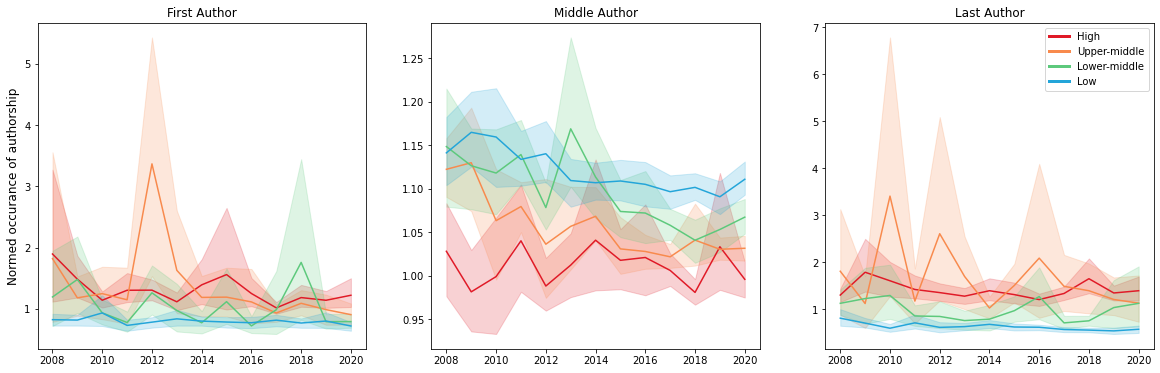

In [63]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(20,6))
ax0=plot_line(merge_role,'F',ax[0],'First Author')
ax0.set_ylabel("Normed occurance of authorship",fontsize=12)
ax1=plot_line(merge_role,'M',ax[1],'Middle Author')
ax2=plot_line(merge_role,'L',ax[2],'Last Author')

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['High', 'Upper-middle', 'Lower-middle','Low']
plt.legend(lines, labels)
#plt.savefig(authorship_norm_ann_plot_path,bbox_inches='tight')

,year,Code,role,raw,shuffle,ratio,ingroup
1304,2012,BGR,F,1,0.10,10.000000,UM
1310,2012,BRA,F,4,6.70,0.597015,UM
1327,2012,CHN,F,12,8.15,1.472393,UM
1376,2012,GAB,F,1,0.90,1.111111,UM
1447,2012,LBN,F,1,0.10,10.000000,UM
1468,2012,MDV,F,1,0.20,5.000000,UM
1470,2012,MEX,F,1,2.30,0.434783,UM
1486,2012,MUS,F,1,0.55,1.818182,UM
1491,2012,MYS,F,2,1.60,1.250000,UM
1523,2012,PER,F,1,2.70,0.370370,UM
